## Import Libraries and Configuration Settings

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
# !pip install imblearn

from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from collections import Counter

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

import joblib
import os
from pathlib import Path

RANDOM_STATE = 824


## Data Understanding

In [2]:
# Resolusi lokasi folder data/ (berjalan baik dari root repo maupun dari dalam subfolder notebooks/)
DATA_DIR = Path('data') if Path('data').is_dir() else Path('../data')
train_df = pd.read_csv(DATA_DIR / 'train.csv')
test_df = pd.read_csv(DATA_DIR / 'test.csv')
sample_submission = pd.read_csv(DATA_DIR / 'sample_submission.csv')

print(f'Format submisi:\n{sample_submission.head()}')

print(f'Panjang train dataset = {len(train_df)}')
print(f'Panjang test dataset = {len(test_df)}')

train_df.describe()
# test_df.describe()

# print(train_df.head())

Format submisi:
         id  is_canceled
0  5cb6f473            0
1  c06b4ab3            0
2  22bf3fc3            0
3  25408a48            0
4  621586b6            0
Panjang train dataset = 27373
Panjang test dataset = 6844


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
count,26564.000000,24338.000000,27373.000000,27373.000000,26291.000000,26250.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,2.533500e+04,24873.000000,27373.000000
mean,1.845242,0.117388,0.814854,2.206517,0.030200,85.379429,2023.820115,7.399664,15.537537,0.025171,0.021883,0.144887,1.716980e+06,0.666948,0.327659
std,0.517974,0.425761,0.875146,1.421603,0.171142,85.969638,0.384099,3.074788,8.773321,0.156646,0.356353,1.693652,5.879368e+05,0.798363,0.469368
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2023.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,17.000000,2024.000000,5.000000,8.000000,0.000000,0.000000,0.000000,1.338000e+06,0.000000,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,58.000000,2024.000000,8.000000,16.000000,0.000000,0.000000,0.000000,1.644000e+06,0.000000,0.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,126.000000,2024.000000,10.000000,23.000000,0.000000,0.000000,0.000000,2.019000e+06,1.000000,1.000000
max,4.000000,10.000000,7.000000,17.000000,1.000000,448.000000,2024.000000,12.000000,31.000000,1.000000,13.000000,58.000000,9.165000e+06,5.000000,1.000000


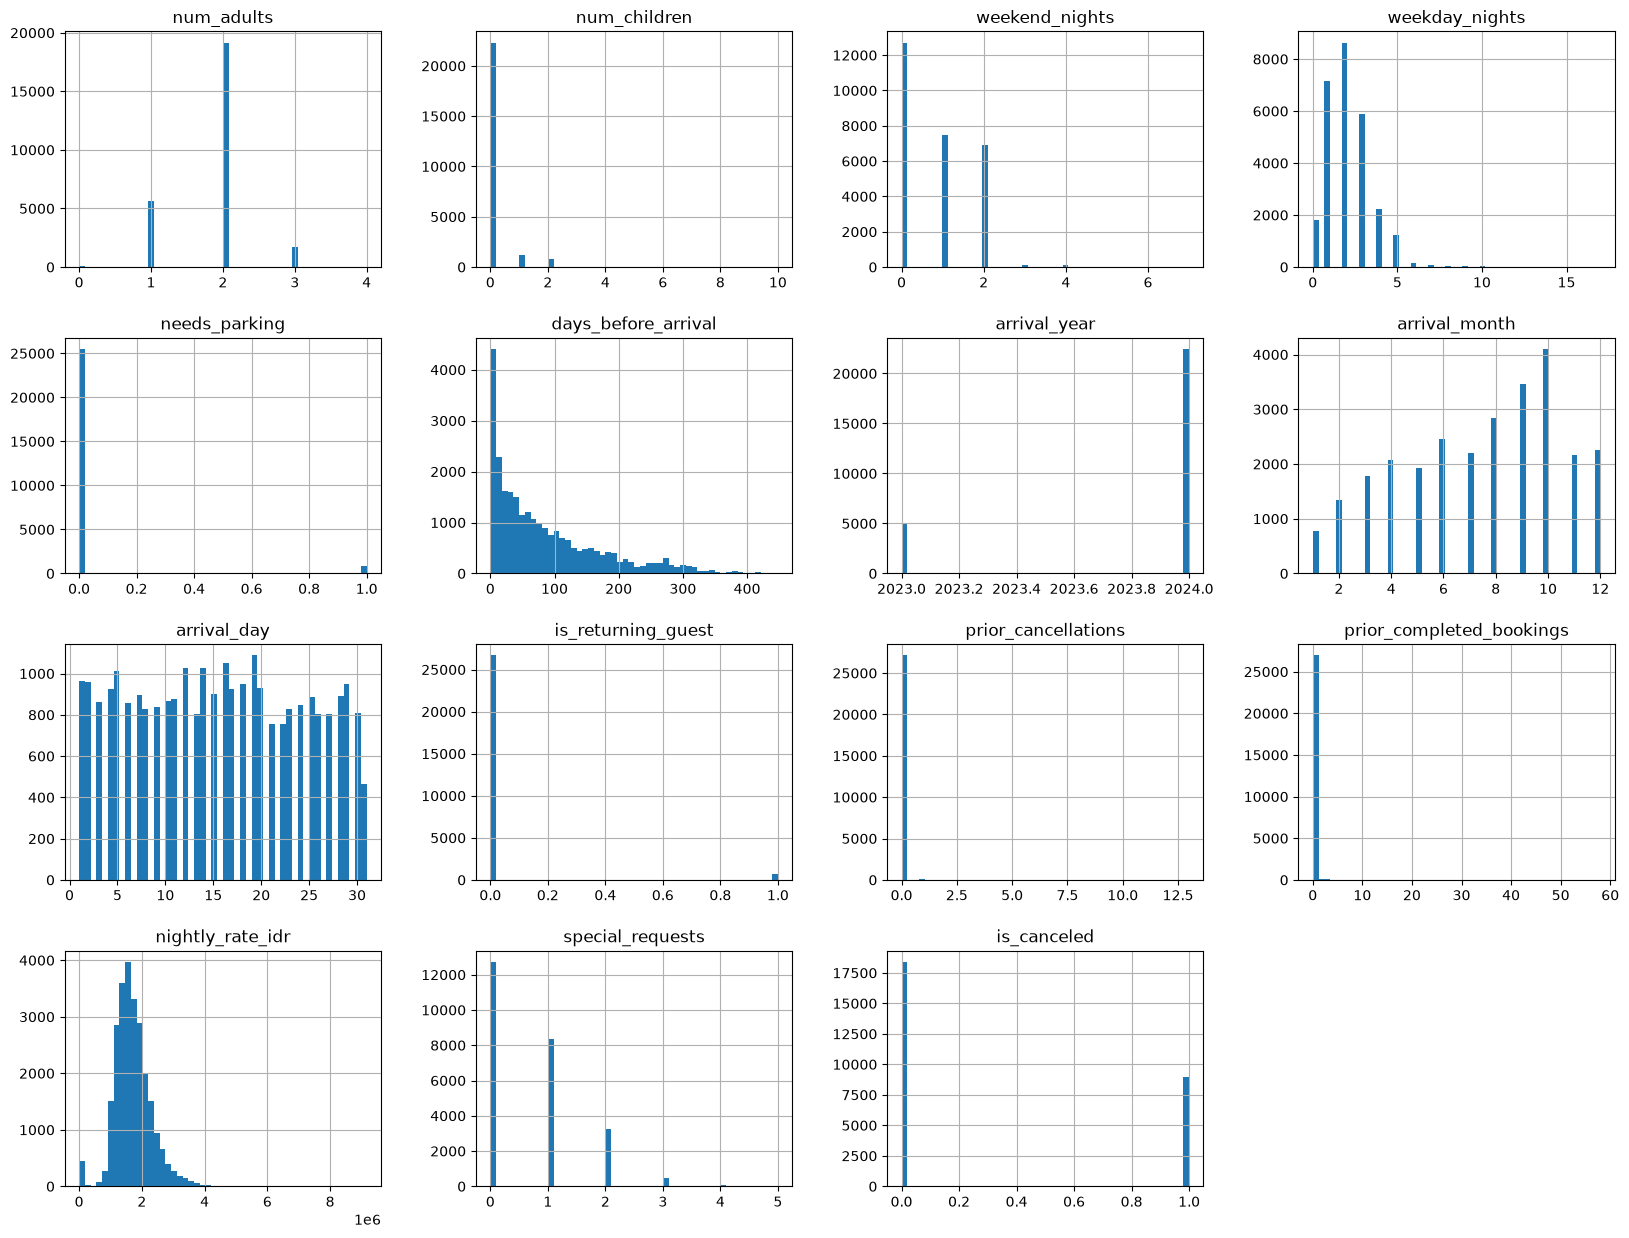

In [3]:
train_df.hist(bins=50, figsize=(20,15))
plt.show()

In [4]:
print('Standard Correlation Coefficient (Pearson\'s r)')

corr_matrix = train_df.corr(numeric_only=True)
corr_matrix['is_canceled'].sort_values(ascending = False)

Standard Correlation Coefficient (Pearson's r)


is_canceled                 1.000000
days_before_arrival         0.440316
arrival_year                0.179826
nightly_rate_idr            0.134092
weekday_nights              0.097226
num_adults                  0.088446
weekend_nights              0.060797
num_children                0.030856
arrival_day                 0.020005
arrival_month              -0.015912
prior_cancellations        -0.035006
prior_completed_bookings   -0.058894
needs_parking              -0.085504
is_returning_guest         -0.107207
special_requests           -0.257996
Name: is_canceled, dtype: float64

## Data Cleaning

### Missing Value Handling

In [5]:
# referensi: https://www.kaggle.com/code/alexisbcook/handling-missing-values

# ========== MISSING VALUE HANDLING ==========
# ===== Show missing values =====
# 1. Train DF
print('Train DF Missing Values')
total_cells = np.prod(train_df.shape)
missing_values_count = train_df.isnull().sum()
# print(missing_values_count)
total_missing = missing_values_count.sum()
percent_missing = (total_missing/total_cells) * 100
print(f'Total missing values = {missing_values_count.sum()}. Missing percentage = {percent_missing}%\n\n')

# 2. Test DF
print('Test DF Missing Values')
total_cells = np.prod(test_df.shape)
missing_values_count = test_df.isnull().sum()
# print(missing_values_count)
total_missing = missing_values_count.sum()
percent_missing = (total_missing/total_cells) * 100
print(f'Total missing values = {missing_values_count.sum()}. Missing percentage = {percent_missing}%\n\n')

# cek hasil jika drop missing values di train_df
train_df_cleaned = train_df.copy()
train_df_cleaned = train_df_cleaned.dropna()
print(f'Training dataset sebelum drop missing vals: {len(train_df)}')
print(f'Training dataset setelah drop missing vals: {len(train_df_cleaned)}\n\n')

# fungsi untuk mengisi nilai kosong pada dataframe
def clean_df(df, columns, method, train_ref=None):
    if df is None:
        print('df invalid')
    if columns is None:
        print('columns invalid')

    ref = train_ref if train_ref is not None else df

    if method == 'median' or method == 'mode':
        for col in columns:
            if method == 'median':
                filler = ref[col].median()
            if method == 'mode':
                filler = ref[col].mode()[0]
            df[col] = df[col].fillna(filler)
        return df
    else:
        print('method invalid')
        return None


# ===== Clean missing values =====
# 1. Train DF
train_df_cleaned = train_df.copy() # reset dataframe training
numerical_columns = ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 
    'days_before_arrival', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 
    'special_requests']
train_df_cleaned = clean_df(train_df_cleaned, numerical_columns, 'median')

categorical_columns = ['needs_parking', 'arrival_year', 'arrival_month', 'arrival_day', 
    'is_returning_guest', 'meal_package', 'room_category', 'booking_channel']
train_df_cleaned = clean_df(train_df_cleaned, categorical_columns, 'mode')
print(f'Sisa missing train_df values setelah cleaning = {train_df_cleaned.isnull().sum().sum()}')
print(f'Panjang train_df_cleaned setelah cleaning = {len(train_df_cleaned)}')


# 2. Test DF
test_df_cleaned = test_df.copy()
test_df_cleaned = clean_df(test_df_cleaned, numerical_columns, 'median', test_df)
test_df_cleaned = clean_df(test_df_cleaned, categorical_columns, 'mode', test_df)

print(f'Sisa missing test_df values setelah cleaning = {test_df_cleaned.isnull().sum().sum()}')
print(f'Panjang test_df_cleaned setelah cleaning = {len(test_df_cleaned)}\n')

Train DF Missing Values
Total missing values = 13349. Missing percentage = 2.566685958310821%


Test DF Missing Values
Total missing values = 3281. Missing percentage = 2.6633222936554324%


Training dataset sebelum drop missing vals: 27373
Training dataset setelah drop missing vals: 16636


Sisa missing train_df values setelah cleaning = 0
Panjang train_df_cleaned setelah cleaning = 27373
Sisa missing test_df values setelah cleaning = 0
Panjang test_df_cleaned setelah cleaning = 6844



> Karena jumlah data yang terbuang cukup banyak, maka baris dengan missing value tidak sebaiknya dihapus, melainkan diisi dengan median atau modus. 

### Duplicate and Invalid Data Handling

In [6]:
# ========== DUPLICATE VALUES HANDLING ==========
print(f'Nilai ganda training = {train_df.duplicated().sum()}\n\n')


# ========== INVALID VALUE HANDLING ==========
# 1. Train DF
# cek nilai negatif
numeric_train_df = train_df_cleaned.select_dtypes(include='number')
print(f'Jumlah nilai negatif pada data train: {(numeric_train_df<0).sum().sum()}')

# cek nilai yang tidak seharusnya 0
no_adults = (train_df_cleaned['num_adults'] == 0)
print(f'Banyak pesanan tanpa orang dewasa = {no_adults.sum()}')
no_nights = ((train_df_cleaned['weekend_nights'] + train_df_cleaned['weekday_nights']) == 0)
print(f'Banyak pesanan dengan jumlah malam 0 = {no_nights.sum()}')

# cek tanggal invalid
date_df = train_df_cleaned[['arrival_year', 'arrival_month', 'arrival_day']].rename(
    columns={'arrival_year': 'year', 'arrival_month': 'month', 'arrival_day': 'day'}
)
invalid_dates = pd.to_datetime(date_df, errors='coerce').isna()
print(f"Banyak tanggal invalid: {invalid_dates.sum()}")

# hapus data invalid
train_df_cleaned = train_df_cleaned[(numeric_train_df >= 0).all(axis=1)].reset_index(drop=True)
valid_mask = (
    (~no_adults) &
    (~no_nights) &
    (~invalid_dates)
)

train_df_cleaned = train_df_cleaned[valid_mask].reset_index(drop=True)
print(f'Panjang train_df_cleaned setelah hapus data invalid = {len(train_df_cleaned)}')

# 2. Test DF
# cek nilai negatif
numeric_test_df = test_df_cleaned.select_dtypes(include='number')
print(f'Jumlah nilai negatif pada data test: {(numeric_test_df<0).sum().sum()}')

# cek nilai yang tidak seharusnya 0
no_adults = (test_df_cleaned['num_adults'] == 0)
print(f'Banyak pesanan tanpa orang dewasa = {no_adults.sum()}')
no_nights = ((test_df_cleaned['weekend_nights'] + test_df_cleaned['weekday_nights']) == 0)
print(f'Banyak pesanan dengan jumlah malam 0 = {no_nights.sum()}')

# cek tanggal invalid
date_df = test_df_cleaned[['arrival_year', 'arrival_month', 'arrival_day']].rename(
    columns={'arrival_year': 'year', 'arrival_month': 'month', 'arrival_day': 'day'}
)
invalid_dates = pd.to_datetime(date_df, errors='coerce').isna()
print(f"Banyak tanggal invalid: {invalid_dates.sum()}")

# isi data invalid dengan median
# Karena untuk test_df, baris tidak boleh dihapus
median_train_adults = train_df_cleaned['num_adults'].median()
test_df_cleaned.loc[no_adults, 'num_adults'] = median_train_adults

median_weekday_nights = train_df_cleaned['weekday_nights'].median()
test_df_cleaned.loc[no_nights, 'weekday_nights'] = median_weekday_nights

print(f'Panjang test_df_cleaned setelah fill data invalid = {len(test_df_cleaned)}')

Nilai ganda training = 0


Jumlah nilai negatif pada data train: 0
Banyak pesanan tanpa orang dewasa = 106
Banyak pesanan dengan jumlah malam 0 = 64
Banyak tanggal invalid: 0
Panjang train_df_cleaned setelah hapus data invalid = 27203
Jumlah nilai negatif pada data test: 0
Banyak pesanan tanpa orang dewasa = 22
Banyak pesanan dengan jumlah malam 0 = 9
Banyak tanggal invalid: 0
Panjang test_df_cleaned setelah fill data invalid = 6844


> Di sisi lain, jumlah data invalid cukup sedikit (< 200 baris), sehingga dihapus tidak masalah.

## Data Transformation

### Categorical Data Encoding

In [7]:
# encoding categorical jadi numerical
train_df_encoded = train_df_cleaned.copy()
test_df_encoded = test_df_cleaned.copy()

ordinal_maps = {
    'meal_package': {'Room Only': 1, 'Breakfast': 2, 'Half Board': 3, 'Full Board': 4}
}
for col, mapping in ordinal_maps.items():
    train_df_encoded[col] = train_df_encoded[col].map(mapping)
    test_df_encoded[col] = test_df_encoded[col].map(mapping)

# reference: https://www.kaggle.com/discussions/getting-started/114797
# room category harus dilakukan one hot encoding karena "show no order or quality"
# booking channel diasumsikan juga demikian
train_df_encoded = pd.get_dummies(train_df_encoded, columns=['room_category', 'booking_channel'], drop_first=True)
test_df_encoded = pd.get_dummies(test_df_encoded, columns=['room_category', 'booking_channel'], drop_first=True)

print("Hasil encoding train_df:")
print(train_df_encoded.head(5))
print("Hasil encoding test_df:")
print(test_df_encoded.head(5))

Hasil encoding train_df:
         id  num_adults  num_children  weekend_nights  weekday_nights  \
0  57152f82         2.0           0.0               1               2   
1  af2ec71b         2.0           0.0               2               1   
2  5d5469ab         3.0           0.0               1               2   
3  d2df0369         2.0           1.0               2               1   
4  91d253db         2.0           0.0               0               1   

   meal_package  needs_parking  days_before_arrival  arrival_year  \
0             2            0.0                 88.0          2024   
1             3            0.0                120.0          2023   
2             2            0.0                209.0          2024   
3             2            0.0                 93.0          2024   
4             1            0.0                 14.0          2024   

   arrival_month  ...  room_category_Type B  room_category_Type C  \
0              4  ...                  True         

### Scaling \(Standardization\)

In [8]:
# Gunakan StandardScaler() dengan asumsi data numerik terdistribusi normal
# reference: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

scaler = StandardScaler()
train_df_encoded[numerical_columns] = scaler.fit_transform(train_df_encoded[numerical_columns])
test_df_encoded[numerical_columns] = scaler.transform(test_df_encoded[numerical_columns])

print(train_df_encoded.head())
print(test_df_encoded.head())

train_df_encoded.describe()
test_df_encoded.describe()

         id  num_adults  num_children  weekend_nights  weekday_nights  \
0  57152f82    0.285848     -0.251437        0.209944       -0.148402   
1  af2ec71b    0.285848     -0.251437        1.352625       -0.853182   
2  5d5469ab    2.291504     -0.251437        0.209944       -0.148402   
3  d2df0369    0.285848      2.342362        1.352625       -0.853182   
4  91d253db    0.285848     -0.251437       -0.932737       -0.853182   

   meal_package  needs_parking  days_before_arrival  arrival_year  \
0             2            0.0             0.044166          2024   
1             3            0.0             0.423374          2023   
2             2            0.0             1.478044          2024   
3             2            0.0             0.103418          2024   
4             1            0.0            -0.832750          2024   

   arrival_month  ...  room_category_Type B  room_category_Type C  \
0              4  ...                  True                 False   
1       

,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests
count,6844.000000,6844.000000,6844.000000,6844.000000,6844.000000,6844.000000,6844.000000,6844.000000,6844.000000,6844.000000,6844.000000,6844.000000,6844.000000,6844.000000,6844.000000
mean,-0.005740,0.024846,-0.022465,-0.001762,1.945500,0.032291,-0.001297,2023.818235,7.401812,15.702659,0.027323,0.026389,0.021415,-0.015168,0.010455
std,1.007972,1.039635,0.981326,0.970874,0.459474,0.176785,0.999463,0.385679,3.050240,8.681514,0.163035,1.242863,1.128652,0.979831,0.995200
min,-1.719808,-0.251437,-0.932737,-1.557961,1.000000,0.000000,-0.998654,2023.000000,1.000000,1.000000,0.000000,-0.061507,-0.085680,-3.066913,-0.770564
25%,0.285848,-0.251437,-0.932737,-0.853182,2.000000,0.000000,-0.773499,2024.000000,5.000000,8.000000,0.000000,-0.061507,-0.085680,-0.621664,-0.770564
50%,0.285848,-0.251437,0.209944,-0.148402,2.000000,0.000000,-0.323191,2024.000000,8.000000,16.000000,0.000000,-0.061507,-0.085680,-0.132257,-0.770564
75%,0.285848,-0.251437,1.352625,0.556378,2.000000,0.000000,0.435224,2024.000000,10.000000,23.000000,0.000000,-0.061507,-0.085680,0.448244,0.504554
max,4.297161,7.529961,5.923349,10.423293,4.000000,1.000000,4.250997,2024.000000,12.000000,31.000000,1.000000,36.311856,31.116568,7.114181,5.605025


### Imbalanced Data Handling

In [9]:
# Gunakan SMOTE untuk menambah data class yang imba
# hanya terapkan untuk training dataset
# Pisahkan X dan y
X_train_encoded = train_df_encoded.drop(columns=['is_canceled', 'id']).copy()
y_train_encoded = train_df_encoded['is_canceled'].copy()

X_train_balanced = X_train_encoded
y_train_balanced = y_train_encoded

print(f"Data sebelum SMOTE: {y_train_balanced.value_counts().to_dict()}")

# Terapkan SMOTE
smote = SMOTE(random_state=RANDOM_STATE)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_encoded, y_train_encoded)

print(f"Data setelah SMOTE: {y_train_balanced.value_counts().to_dict()}")

Data sebelum SMOTE: {0: 18268, 1: 8935}


Data setelah SMOTE: {1: 18268, 0: 18268}


## Feature Selection

In [10]:
# Feature selection sebenarnya ada filter dan wrapper, tapi untuk ini dilakukan filter dulu
# TODO: tambahkan metode feature selection tipe wrapper saat modeling
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k=10)
X_train_selected = selector.fit_transform(X_train_balanced, y_train_balanced)

feature_summary = pd.DataFrame({
    'Feature': X_train_balanced.columns,
    'Score': selector.scores_
}).sort_values(by='Score', ascending=False).reset_index(drop=True)

print("Features score (sorted):")
print(feature_summary)

selected_features = feature_summary.head(15)['Feature'].tolist()

# Gunakan 15 fitur terbaik untuk KNN
X_train_final = X_train_balanced[selected_features]
X_test_final = test_df_encoded[selected_features]
print(f"\nJumlah fitur yang digunakan: {X_train_final.shape[1]}")

Features score (sorted):
                                Feature        Score
0                   days_before_arrival  8181.838428
1                      special_requests  3390.638722
2                          arrival_year  1501.950908
3                      nightly_rate_idr   706.335284
4                    is_returning_guest   659.003064
5   booking_channel_Online Travel Agent   577.382680
6             booking_channel_Corporate   553.534144
7                         needs_parking   376.244815
8                            num_adults   348.102839
9                        weekday_nights   337.318398
10        booking_channel_Complimentary   289.500918
11             prior_completed_bookings   194.192925
12                       weekend_nights   134.870212
13                  prior_cancellations    69.925067
14                         num_children    38.969722
15                 room_category_Type G    36.604861
16        booking_channel_Offline Agent    30.063945
17                   

## Dimensionality Reduction

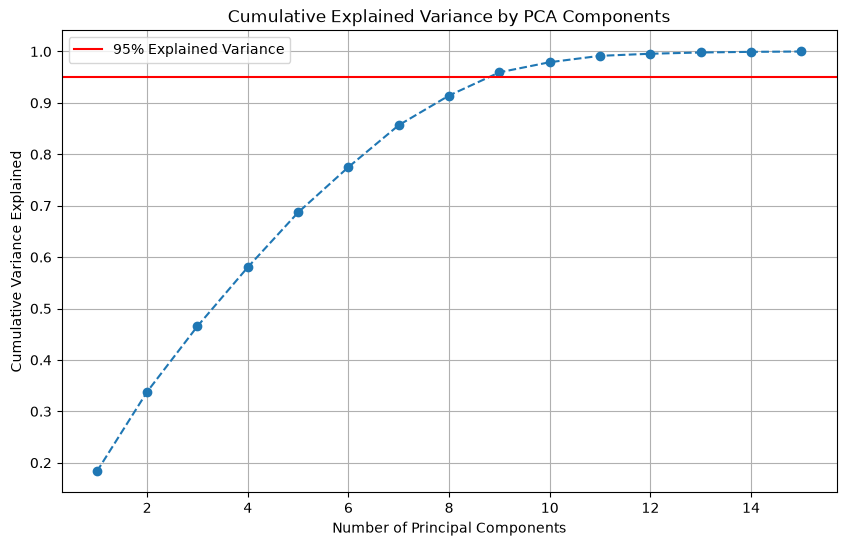

Dimensi sebelum PCA (hasil feature selection): 15
Dimensi setelah PCA (mempertahankan 95% varians): 9


In [11]:
# Jika dataset memiliki jumlah fitur yang besar, reduksi dimensi dapat digunakan untuk mengurangi dimensi tanpa
# kehilangan informasi penting. Teknik seperti Principal Component Analysis (PCA) sering digunakan pada tahap ini.

from sklearn.decomposition import PCA

pca_eval = PCA(random_state=RANDOM_STATE)
pca_eval.fit(X_train_final)

cumulative_variance = np.cumsum(pca_eval.explained_variance_ratio_)

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.axhline(y=0.95, color='r', linestyle='-', label='95% Explained Variance')
plt.title('Cumulative Explained Variance by PCA Components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Variance Explained')
plt.legend()
plt.grid(True)
plt.show()

pca_final = PCA(n_components=0.95, random_state=RANDOM_STATE)
X_train_pca = pca_final.fit_transform(X_train_final)

print(f"Dimensi sebelum PCA (hasil feature selection): {X_train_final.shape[1]}")
print(f"Dimensi setelah PCA (mempertahankan 95% varians): {X_train_pca.shape[1]}")

X_test_pca = pca_final.transform(X_test_final)

# khusus KNN
# X_train_pca = X_train_final.to_numpy(dtype=float)
# X_test_pca = X_test_final.to_numpy(dtype=float)
# print(f"Dimensi fitur untuk KNN: {X_train_pca.shape[1]} fitur (tanpa reduksi PCA)")

## Modeling and Validation

In [12]:
# algoritma KNN from scratch
# reference: https://www.kaggle.com/code/fareselmenshawii/knn-from-scratch
class KNN:
    """
    Parameters:
    -----------
    k : int, optional (default=5)
        Number of neighbors to use in the majority vote.
    metric : string, optional (default='minkowski')
        Distance metric to use in calculating distance
    p : int, optional (default=2)
        Power parameter for minkowski metric
    batch_size : int, optional
        Number of samples to be processed at once
    weights : {'uniform', 'inverted'}, optional (default='uniform')
        Weight function used in prediction. 'uniform' assigns equal weight to all neighbors.
        'inverted' assigns weights inversely proportional to distance (1 / (d + 1e-5)).
    """
    def __init__(self, k=5, metric='minkowski', p=2, batch_size=256, weights='uniform'):
        self.k = k
        self.metric = metric
        self.batch_size = batch_size
        if weights not in {'uniform', 'inverted'}:
            raise ValueError(f"weights must be 'uniform' or 'inverted', got '{weights}'")
        
        if weights == 'inverted' or weights == 'uniform':
            self.weights = weights
        else:
            self.weights = 'uniform'
            print('Weights of KNN set to uniform')
        
        if self.metric=='manhattan':
            self.p = 1
        elif self.metric=='euclidean':
            self.p = 2
        else:
            self.p = p

    def minkowski_distance(self, x1, x2):
        """
        Calculate the Minkowski distance between two data points.
        Also handles Manhattan (p=1) and Euclidean (p=2) distance 
        reference: https://www.geeksforgeeks.org/maths/minskowski-distance/
        """
        return np.power(np.sum(np.abs(np.array(x1) - np.array(x2)) ** self.p), 1 / self.p)

    def hamming_distance(self, x1, x2):
        """
        Calculate normalized Hamming distance
        """
        return np.mean(x1 != x2)

    def _distances(self, Xb):
        """
        Calculate distances for Minkowski (including Manhattan and Euclidean) and Hamming
        Simplification and modification (into batch-based calculations) from previous functions
        """
        n_feat = self.X_train.shape[1] # number of features
        
        # Initialization of D (Xb length x X_train length)
        D = np.zeros((Xb.shape[0], self.X_train.shape[0]))

        if self.metric == 'hamming':
            for j in range(n_feat):
                D += (Xb[:, j][:, None] != self.X_train[:, j][None, :])
            return D / n_feat # equals to np.mean(x1 != x2)

        for j in range(n_feat):
            D += np.abs(Xb[:, j][:, None] - self.X_train[:, j][None, :]) ** self.p
        return D ** (1 / self.p)

    def fit(self, X_train, y_train):
        self.X_train = np.asarray(X_train, dtype=float)
        self.y_train = np.asarray(y_train)
        self.classes_ = np.unique(self.y_train)

    def predict(self, X):
        """
        Predict on batches with support for uniform and inverted distance weighting
        """
        X = np.asarray(X, dtype=float)
        preds = []

        for start in range(0, X.shape[0], self.batch_size):
            Xb = X[start:start + self.batch_size]
            D = self._distances(Xb)

            # Take only k smallest distances
            idx = np.argpartition(D, self.k - 1, axis=1)[:, :self.k]
            labels = self.y_train[idx]

            if self.weights == 'inverted':
                k_dist = np.take_along_axis(D, idx, axis=1)
                w = 1.0 / (k_dist + 1e-5)
                scores = np.stack([(w * (labels == c)).sum(axis=1) for c in self.classes_], axis=1)
                preds.append(self.classes_[np.argmax(scores, axis=1)])
            else:
                # Majority Vote (uniform)
                counts = np.stack([(labels == c).sum(axis=1) for c in self.classes_], axis=1)
                preds.append(self.classes_[np.argmax(counts, axis=1)])

        return np.concatenate(preds)

    def _predict(self, x):
        """
        Predicts the class label for a single example (helper).
        """
        if self.metric == 'hamming':
            distances = np.array([self.hamming_distance(x, x_train) for x_train in self.X_train])
        else:
            distances = np.array([self.minkowski_distance(x, x_train) for x_train in self.X_train])
        
        k_idx_sorted = np.argsort(distances)[: self.k]
        labels = self.y_train[k_idx_sorted]
        
        if self.weights == 'inverted':
            k_distances = distances[k_idx_sorted]
            w = 1.0 / (k_distances + 1e-5)
            scores = {c: float((w * (labels == c)).sum()) for c in self.classes_}
            return max(scores, key=scores.get)
        else:
            labels_list = list(labels)
            return max(labels_list, key=labels_list.count)
        
    def predict_proba(self, X):
        """
        Predict class probabilities
        Batch-based with support for uniform and inverted distance weighting
        Returns array of shape (n_samples, n_classes)
        """
        X = np.asarray(X, dtype=float)
        classes = np.unique(self.y_train)
        probs = []
        
        for start in range(0, X.shape[0], self.batch_size):
            Xb = X[start:start + self.batch_size]
            D = self._distances(Xb)
            
            idx = np.argpartition(D, self.k - 1, axis=1)[:, :self.k]
            labels = self.y_train[idx]
            
            if self.weights == 'inverted':
                k_dist = np.take_along_axis(D, idx, axis=1)
                w = 1.0 / (k_dist + 1e-5)
                total_w = w.sum(axis=1, keepdims=True)
                scores = np.stack([(w * (labels == c)).sum(axis=1) for c in classes], axis=1)
                batch_proba = scores / total_w
                probs.append(batch_proba)
            else:
                counts = np.stack([(labels == c).sum(axis=1) for c in classes], axis=1)
                batch_proba = counts / self.k
                probs.append(batch_proba)

        return np.vstack(probs)

# Daftarkan modul agar save/load pickle konsisten lintas script
KNN.__module__ = 'src.models.knn'


Asumsi urutan SMOTE benar: True
Ukuran data train: (31055, 9), Ukuran data validation: (5481, 9)

Validation: 4081 baris asli, 1400 baris sintetis (tidak dinilai)

[KNN | k=5, metric=euclidean, p=2, weights=inverted] -> Mean Acc: 0.83948 | Mean Macro F1: 0.83946 (±0.00320)
[KNN | k=3, metric=euclidean, p=2, weights=inverted] -> Mean Acc: 0.83668 | Mean Macro F1: 0.83666 (±0.00254)
[KNN | k=5, metric=euclidean, p=2, weights=uniform] -> Mean Acc: 0.81214 | Mean Macro F1: 0.81001 (±0.00177)
[KNN | k=5, metric=euclidean, p=2, weights=inverted] -> Mean Acc: 0.83001 | Mean Macro F1: 0.82913 (±0.00200)
[KNN | k=3, metric=euclidean, p=2, weights=uniform] -> Mean Acc: 0.83256 | Mean Macro F1: 0.83255 (±0.00201)
[KNN | k=3, metric=euclidean, p=2, weights=inverted] -> Mean Acc: 0.83664 | Mean Macro F1: 0.83632 (±0.00287)
              precision    recall  f1-score   support

           0       0.87      0.86      0.87      2741
           1       0.72      0.73      0.73      1340

    accuracy  

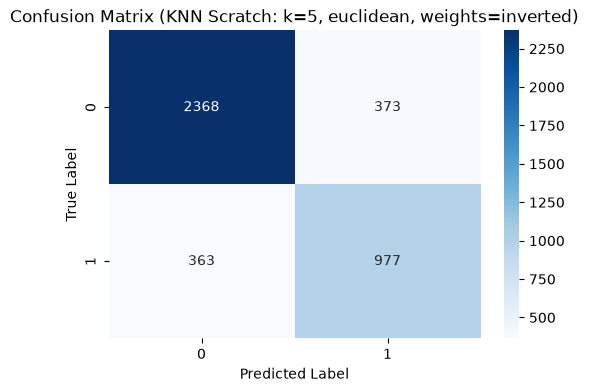

In [13]:
# Split data training jadi training and validation
# Karena menggunakan SMOTE, splitting harus disesuaikan karena ada baris asli dan sintetis
n_orig = len(X_train_encoded)
is_orig = np.arange(len(y_train_balanced)) < n_orig

a = X_train_balanced.iloc[:n_orig].to_numpy(dtype=float)
b = X_train_encoded.to_numpy(dtype=float)
print("Asumsi urutan SMOTE benar:", np.allclose(a, b))


# Split, jaga proporsi label x asli/sintetis
strat_key = np.asarray(y_train_balanced).astype(int) * 2 + is_orig.astype(int)
X_tr, X_val, y_tr, y_val, orig_tr, orig_val = train_test_split(
    X_train_pca, y_train_balanced, is_orig,
    test_size=0.15,
    random_state=RANDOM_STATE,
    stratify=strat_key
)
X_tr, X_val = np.asarray(X_tr), np.asarray(X_val)
y_tr, y_val = np.asarray(y_tr), np.asarray(y_val)

print(f'Ukuran data train: {X_tr.shape}, Ukuran data validation: {X_val.shape}\n')
print(f'Validation: {orig_val.sum()} baris asli, {(~orig_val).sum()} baris sintetis (tidak dinilai)\n')


# Buat deretan configs untuk dipilih
configs = [
    {'k': 5, 'metric':'euclidean', 'p':2, 'weights':'inverted', 'prob_thres':0.45},
    {'k': 3, 'metric':'euclidean', 'p':2, 'weights':'inverted', 'prob_thres':0.45},
    {'k': 5, 'metric':'euclidean', 'p':2, 'weights':'uniform', 'prob_thres':0.65},
    {'k': 5, 'metric':'euclidean', 'p':2, 'weights':'inverted', 'prob_thres':0.65},
    {'k': 3, 'metric':'euclidean', 'p':2, 'weights':'uniform', 'prob_thres':0.65},
    {'k': 3, 'metric':'euclidean', 'p':2, 'weights':'inverted', 'prob_thres':0.65},
]
# Inisialisasi KFolds
k_folds = 5
skf = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=RANDOM_STATE)

best_f1_score = 0
best_config = None

for c in configs:
    fold_accuracies = []
    fold_f1_scores = []
    
    # Loop for each fold
    for fold, (train_idx, val_idx) in enumerate(skf.split(X_tr, y_tr)):
        X_fold_train, X_fold_val = X_tr[train_idx], X_tr[val_idx]
        y_fold_train, y_fold_val = y_tr[train_idx], y_tr[val_idx]
        
        # fitting and predict test, finding accuracy score of each fold and config
        knn_model = KNN(k=c['k'], metric=c['metric'], p=c['p'], weights=c.get('weights', 'uniform'))
        knn_model.fit(X_fold_train, y_fold_train)
        # y_pred_fold = knn_model.predict(X_fold_val) # for predict with 0.5 threshold
        y_pred_fold_std = knn_model.predict_proba(X_fold_val)[:,1]
        y_pred_fold = (y_pred_fold_std>=c['prob_thres'])
        
        fold_accuracies.append(accuracy_score(y_fold_val, y_pred_fold))
        fold_f1_scores.append(f1_score(y_fold_val, y_pred_fold, average='macro'))
    
    # Hitung rata-rata dan standar deviasi dari K-Fold
    mean_acc = np.mean(fold_accuracies)
    mean_f1 = np.mean(fold_f1_scores)
    std_f1 = np.std(fold_f1_scores)
    
    print(f"[KNN | k={c['k']}, metric={c['metric']}, p={c['p']}, weights={c.get('weights', 'uniform')}] -> "
          f"Mean Acc: {mean_acc:.5f} | Mean Macro F1: {mean_f1:.5f} (±{std_f1:.5f})")

    if mean_f1 > best_f1_score:
        best_f1_score = mean_f1
        best_config = c

# Pilih konfigurasi terbaik
final_knn = KNN(k=best_config['k'], metric=best_config['metric'], p=best_config['p'], weights=best_config.get('weights', 'uniform'))

# Fit HANYA pada data asli (tanpa baris sintetis SMOTE agar model tidak bias pas testing)
final_knn.fit(X_tr[orig_tr], y_tr[orig_tr])

# Prediksi validasi konsisten dengan threshold probabilitas terbaik dari K-Fold
val_probs = final_knn.predict_proba(X_val)[:, 1]
val_preds = (val_probs >= best_config['prob_thres']).astype(int)
m = orig_val

# Classification Report
print(classification_report(y_val[m], val_preds[m]))

# Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_val[m], val_preds[m]), annot=True, fmt='d', cmap='Blues')
plt.title(f"Confusion Matrix (KNN Scratch: k={best_config['k']}, {best_config['metric']}, weights={best_config.get('weights', 'uniform')})")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

## Perbandingan dengan scikit-learn (KNeighborsClassifier)

Untuk memvalidasi kebenaran implementasi KNN *from scratch*, dilakukan perbandingan langsung terhadap `sklearn.neighbors.KNeighborsClassifier` pada set validasi asli yang sama. Perbandingan mencakup:
1. Kesepakatan prediksi (*prediction agreement*)
2. Metrik performa (Akurasi, Macro F1, F1-Score kelas positif)
3. Waktu komputasi (waktu *training/fit* dan waktu *inference/predict*)


In [14]:
import time
from sklearn.neighbors import KNeighborsClassifier

print('=== PERBANDINGAN KNN FROM SCRATCH vs SCIKIT-LEARN ===\n')

# Evaluasi model scratch vs scikit-learn pada subset validasi asli
X_eval_tr = X_tr[orig_tr]
y_eval_tr = y_tr[orig_tr]
X_eval_val = X_val[orig_val]
y_eval_val = y_val[orig_val]

compare_rows = []

test_configs = [
    {'k': 3, 'weights': 'uniform', 'metric': 'euclidean'},
    {'k': 3, 'weights': 'inverted', 'metric': 'euclidean'},
    {'k': 5, 'weights': 'uniform', 'metric': 'euclidean'},
    {'k': 5, 'weights': 'inverted', 'metric': 'euclidean'},
    {'k': 7, 'weights': 'uniform', 'metric': 'euclidean'},
    {'k': 7, 'weights': 'inverted', 'metric': 'euclidean'},
]

for cfg in test_configs:
    k_val = cfg['k']
    w_scratch = cfg['weights']
    w_sklearn = 'uniform' if w_scratch == 'uniform' else 'distance'
    
    # 1. KNN Scratch
    t0 = time.perf_counter()
    model_scratch = KNN(k=k_val, metric=cfg['metric'], weights=w_scratch)
    model_scratch.fit(X_eval_tr, y_eval_tr)
    t_fit_scratch = time.perf_counter() - t0
    
    t0 = time.perf_counter()
    preds_scratch = model_scratch.predict(X_eval_val)
    t_pred_scratch = time.perf_counter() - t0
    
    # 2. Scikit-Learn
    t0 = time.perf_counter()
    model_sklearn = KNeighborsClassifier(n_neighbors=k_val, metric=cfg['metric'], weights=w_sklearn)
    model_sklearn.fit(X_eval_tr, y_eval_tr)
    t_fit_sklearn = time.perf_counter() - t0
    
    t0 = time.perf_counter()
    preds_sklearn = model_sklearn.predict(X_eval_val)
    t_pred_sklearn = time.perf_counter() - t0
    
    acc_s = accuracy_score(y_eval_val, preds_scratch)
    acc_sk = accuracy_score(y_eval_val, preds_sklearn)
    f1_s = f1_score(y_eval_val, preds_scratch, average='macro')
    f1_sk = f1_score(y_eval_val, preds_sklearn, average='macro')
    f1_pos_s = f1_score(y_eval_val, preds_scratch, pos_label=1)
    f1_pos_sk = f1_score(y_eval_val, preds_sklearn, pos_label=1)
    agreement = np.mean(preds_scratch == preds_sklearn) * 100.0
    
    compare_rows.append({
        'k': k_val,
        'Weights': w_scratch,
        'Model': 'Scratch',
        'Accuracy': f'{acc_s:.4f}',
        'Macro F1': f'{f1_s:.4f}',
        'F1 (Pos)': f'{f1_pos_s:.4f}',
        'Fit Time (s)': f'{t_fit_scratch:.4f}',
        'Predict Time (s)': f'{t_pred_scratch:.4f}',
        'Agreement (%)': f'{agreement:.2f}%'
    })
    compare_rows.append({
        'k': k_val,
        'Weights': w_scratch,
        'Model': 'scikit-learn',
        'Accuracy': f'{acc_sk:.4f}',
        'Macro F1': f'{f1_sk:.4f}',
        'F1 (Pos)': f'{f1_pos_sk:.4f}',
        'Fit Time (s)': f'{t_fit_sklearn:.4f}',
        'Predict Time (s)': f'{t_pred_sklearn:.4f}',
        'Agreement (%)': '-'
    })

df_compare = pd.DataFrame(compare_rows)
display(df_compare)

# Kesepakatan pada probabilitas dan threshold model terbaik
best_sklearn = KNeighborsClassifier(
    n_neighbors=best_config['k'],
    metric=best_config['metric'],
    weights='distance' if best_config.get('weights') == 'inverted' else 'uniform'
)
best_sklearn.fit(X_eval_tr, y_eval_tr)
sk_val_probs = best_sklearn.predict_proba(X_eval_val)[:, 1]
sk_val_preds = (sk_val_probs >= best_config['prob_thres']).astype(int)
final_agree = np.mean(val_preds[m] == sk_val_preds) * 100.0
print(f"\nKesepakatan Prediksi Model Terbaik (k={best_config['k']}, weights={best_config.get('weights')}, thres={best_config['prob_thres']}) dengan Scikit-Learn: {final_agree:.2f}%")


=== PERBANDINGAN KNN FROM SCRATCH vs SCIKIT-LEARN ===



,k,Weights,Model,Accuracy,Macro F1,F1 (Pos),Fit Time (s),Predict Time (s),Agreement (%)
0,3,uniform,Scratch,0.8162,0.7883,0.7113,0.0007,17.5024,100.00%
1,3,uniform,scikit-learn,0.8162,0.7883,0.7113,0.0656,0.0946,-
2,3,inverted,Scratch,0.8189,0.7928,0.7193,0.0004,14.9075,99.95%
3,3,inverted,scikit-learn,0.8189,0.7928,0.7191,0.0519,0.1010,-
4,5,uniform,Scratch,0.8165,0.7878,0.7098,0.0003,14.0835,100.00%
5,5,uniform,scikit-learn,0.8165,0.7878,0.7098,0.0400,0.1038,-
6,5,inverted,Scratch,0.8211,0.7945,0.7205,0.0002,13.8474,99.95%
7,5,inverted,scikit-learn,0.8211,0.7944,0.7203,0.0499,0.1520,-
8,7,uniform,Scratch,0.8150,0.7836,0.7012,0.0004,13.7367,100.00%
9,7,uniform,scikit-learn,0.8150,0.7836,0.7012,0.0611,0.1162,-



Kesepakatan Prediksi Model Terbaik (k=5, weights=inverted, thres=0.45) dengan Scikit-Learn: 100.00%


## Submission

In [15]:
# bikin submisi yang reproducible

# set seed
np.random.seed(RANDOM_STATE)

OUTPUT_DIR = Path('output') if Path('output').is_dir() else Path('../output')
os.makedirs(OUTPUT_DIR, exist_ok=True)
model_filename = str(OUTPUT_DIR / 'knn.pkl')
joblib.dump(final_knn, model_filename)
print(f"Model berhasil disimpan ke '{model_filename}' (Ukuran: {os.path.getsize(model_filename) / 1024:.2f} KB)")

# Test reloading model
loaded_knn_model = joblib.load(model_filename)
print(f"Model berhasil di-load kembali dari '{model_filename}'!\n")

# Create predictions with loaded model (menggunakan prob_thres terbaik dari K-Fold)
print("Melakukan prediksi pada data test...")
final_submission_knn = KNN(k=best_config['k'], metric=best_config['metric'], p=best_config['p'])
final_submission_knn.fit(X_train_pca[is_orig], y_train_balanced.iloc[:n_orig].to_numpy())

test_probs = final_submission_knn.predict_proba(X_test_pca)[:, 1]
test_predictions = (test_probs >= best_config['prob_thres']).astype(int)
# Create submission
submission = pd.DataFrame({
    'id': test_df['id'],
    'is_canceled': test_predictions.astype(int)
})

# Submission format validations
assert len(submission) == len(sample_submission), "Error: Jumlah baris submisi tidak sesuai!"
assert list(submission.columns) == list(sample_submission.columns), "Error: Nama kolom tidak sesuai!"
assert submission['is_canceled'].isnull().sum() == 0, "Error: Ada nilai kosong (NaN) pada prediksi!"

submission_csv_path = str(OUTPUT_DIR / 'submission_knn.csv')
submission.to_csv(submission_csv_path, index=False)

print(f"File submisi '{submission_csv_path}' berhasil dibuat dan siap dikumpulkan!")
print("\nDistribusi hasil prediksi:")
print(submission['is_canceled'].value_counts())
display(submission.head())

Model berhasil disimpan ke '..\output\knn.pkl' (Ukuran: 1806.91 KB)
Model berhasil di-load kembali dari '..\output\knn.pkl'!

Melakukan prediksi pada data test...
File submisi '..\output\submission_knn.csv' berhasil dibuat dan siap dikumpulkan!

Distribusi hasil prediksi:
is_canceled
0    4841
1    2003
Name: count, dtype: int64


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=f5928910-4999-4958-8a98-3bd08002b179' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>